In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Lagankhel Data analysis and Visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_LagankhelLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.467958,c,2025-10-12 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.085417,c,2025-10-12 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,temperature,24.098778,c,2025-10-12 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.040861,c,2025-10-12 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.285500,c,2025-10-12 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,5509788,Lagankhel (SC - 05) - GD Labs,temperature,17.608334,c,2025-11-27 03:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,03:45:00
996,5509788,Lagankhel (SC - 05) - GD Labs,temperature,17.513667,c,2025-11-27 04:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,04:45:00
997,5509788,Lagankhel (SC - 05) - GD Labs,temperature,17.335708,c,2025-11-27 05:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,05:45:00
998,5509788,Lagankhel (SC - 05) - GD Labs,temperature,17.392500,c,2025-11-27 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,06:45:00


In [3]:
df365.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [4]:
# Convert the date column to a proper datetime value
df365["date"] = pd.to_datetime(df365["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df365.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [5]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2025-10-12,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.180348,c,18,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
1,2025-10-13,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.225965,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
2,2025-10-14,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.162366,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
3,2025-10-15,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.388830,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
4,2025-10-16,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.433402,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
5,2025-10-17,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.882829,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
6,2025-10-18,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.314185,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
7,2025-10-19,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.849708,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
8,2025-10-20,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.298722,c,21,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
9,2025-10-21,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.659470,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_9179/1693882114.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


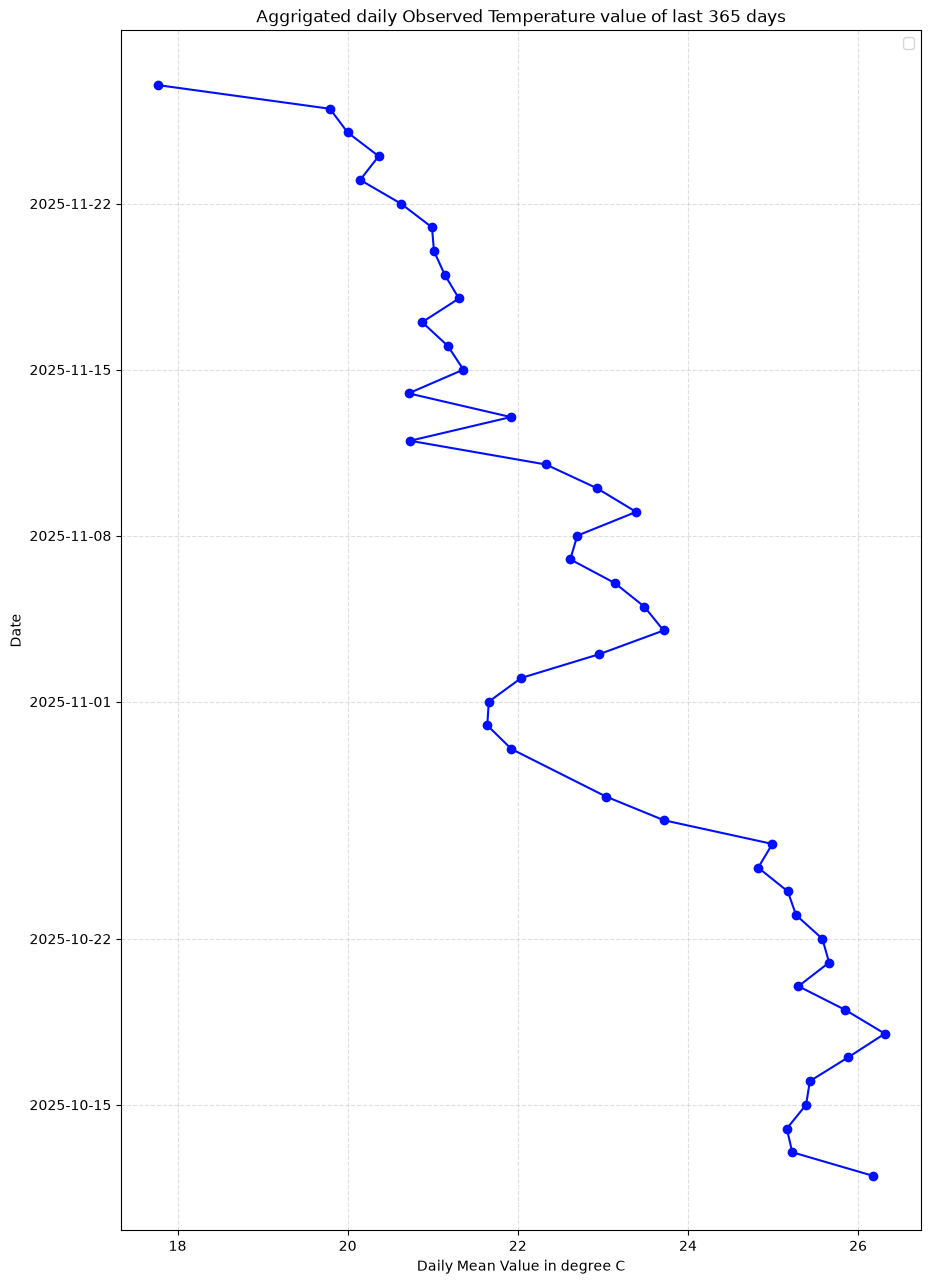

In [6]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 365 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data analysis and Visualization of last 30 days

In [7]:
df30 = pd.read_csv('cleaned_LagankhelLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.1,c,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.5,c,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.3,c,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.8,c,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,temperature,27.8,c,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.3,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
716,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.2,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
717,5509788,Lagankhel (SC - 05) - GD Labs,temperature,21.9,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
718,5509788,Lagankhel (SC - 05) - GD Labs,temperature,21.6,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [8]:
df30.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [9]:
# Convert the date column to a proper datetime value
df30["date"] = pd.to_datetime(df30["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df30.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [10]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-09-12,5509788,Lagankhel (SC - 05) - GD Labs,temperature,27.483333,c,18,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
1,2026-09-13,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.816667,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
2,2026-09-14,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.541667,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
3,2026-09-15,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.445833,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
4,2026-09-16,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.470833,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
5,2026-09-17,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.554167,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
6,2026-09-18,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.216667,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
7,2026-09-19,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.308333,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
8,2026-09-20,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.650000,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
9,2026-09-21,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.166667,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_9179/3570141088.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


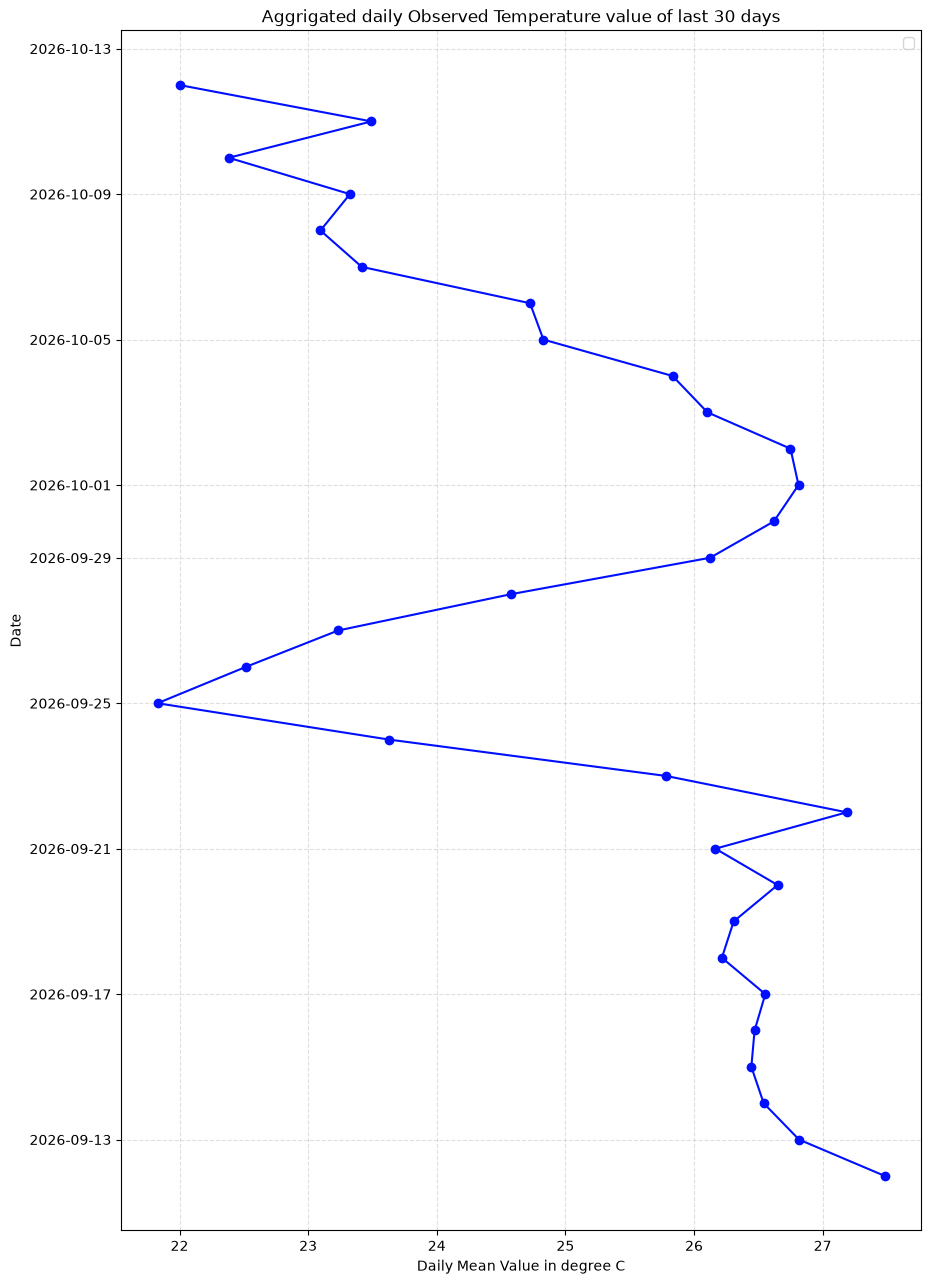

In [11]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 30 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data analysis and Visualization of last 1 week

In [12]:
df7 = pd.read_csv('cleaned_LagankhelLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.8,c,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.9,c,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,temperature,24.8,c,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.3,c,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.0,c,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.3,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.2,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,5509788,Lagankhel (SC - 05) - GD Labs,temperature,21.9,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,5509788,Lagankhel (SC - 05) - GD Labs,temperature,21.6,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [13]:
# Convert the date column to a proper datetime value
df7["date"] = pd.to_datetime(df7["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df7.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]


In [14]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-10-05,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.105556,c,18,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
1,2026-10-06,5509788,Lagankhel (SC - 05) - GD Labs,temperature,24.725000,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
2,2026-10-07,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.416667,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
3,2026-10-08,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.095833,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
4,2026-10-09,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.325000,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
5,2026-10-10,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.383333,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
6,2026-10-11,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.491667,c,24,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient
7,2026-10-12,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.000000,c,6,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_9179/3647158116.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


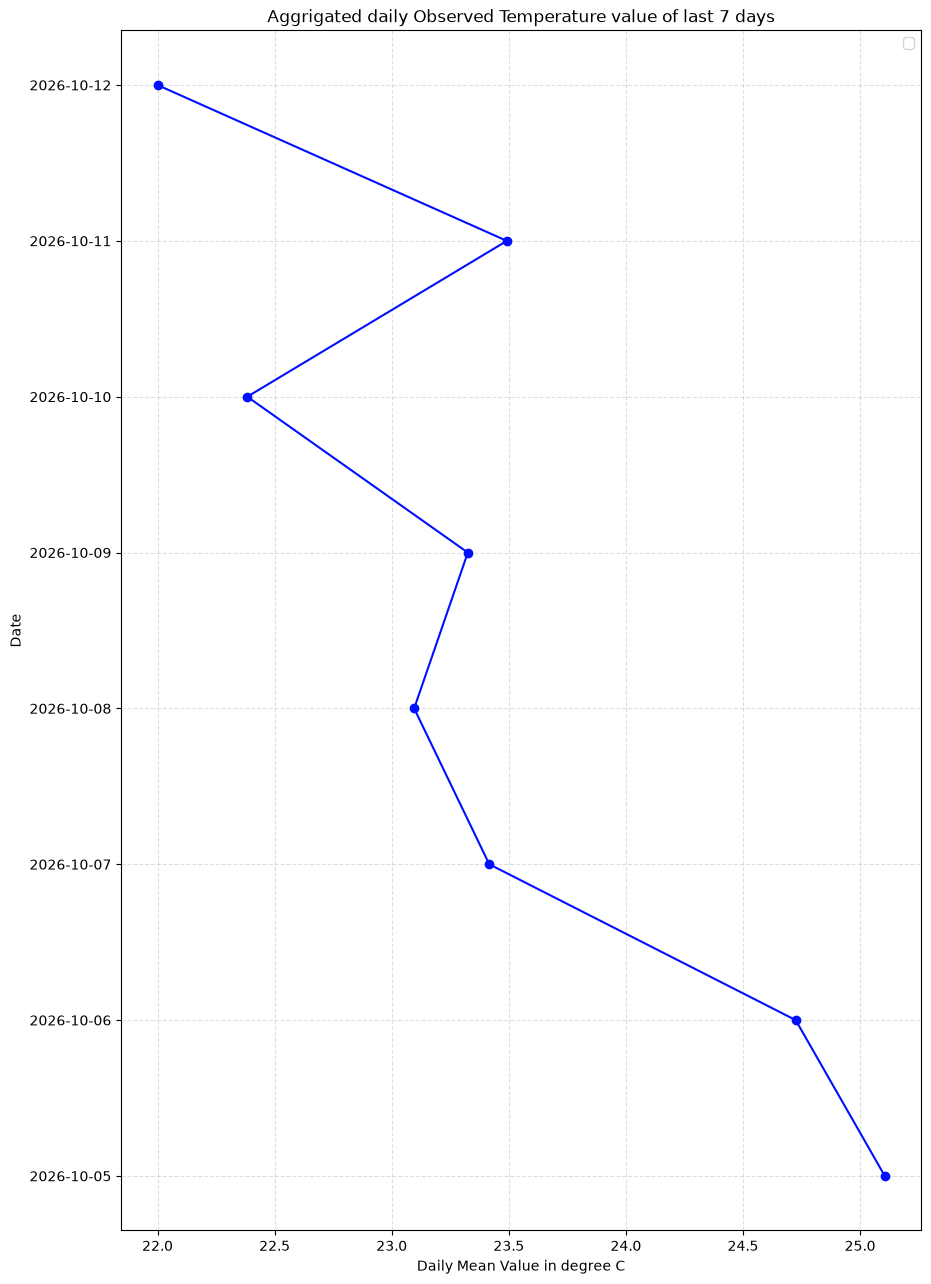

In [15]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 7 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [16]:
df24 = pd.read_csv('cleaned_LagankhelLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,temperature,21.1,c,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,temperature,21.3,c,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,temperature,22.2,c,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,temperature,23.1,c,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,temperature,24.4,c,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.3,c,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,5509788,Lagankhel (SC - 05) - GD Labs,temperature,25.7,c,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.0,c,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,5509788,Lagankhel (SC - 05) - GD Labs,temperature,26.7,c,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,5509788,Lagankhel (SC - 05) - GD Labs,temperature,28.1,c,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [17]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_9179/318776006.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


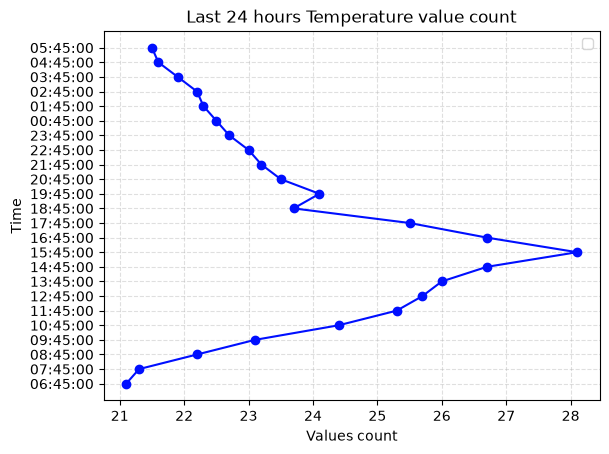

In [18]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Last 24 hours Temperature value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()